In [2]:
from google.colab import drive
import os
import shutil
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Modify the below file path to the path of your uploaded MUC Project folder
#  (clone the github in the instructions document locally and upload to Google Drive)
#
# By copying over the files, this allows you to access helper functions and access the data uploaded

#go back to base content directory
%cd
%cd ../content
#if already downloaded, delete to grab again in case of file changes
%rm -rf muc
#copy over from drive, so we aren't altering anything directly
%cp -r '/content/drive/MyDrive/muc' .
%cd muc

/root
/content
/content/muc


In [4]:
# this function creates all in-line plots. DO NOT DELETE.
import matplotlib
matplotlib.use('Agg')
%matplotlib inline
import matplotlib.pyplot as plt


def plot_data(data, labels=['x','y','z'], title='X,Y,Z Plot'):
    # adjust rcParams as needed to make your graph readable
    plt.rcParams['figure.figsize'] = [10, 5]
    plt.title(title)
    for i in range(len(labels)):
      plt.plot([row[0] for row in data],[row[i+1] for row in data], label=labels[i])
    plt.legend(loc='upper right')
    plt.show()

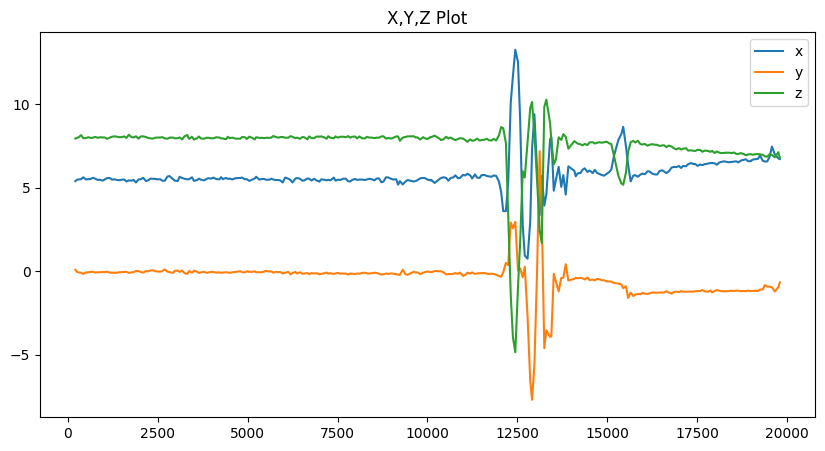

In [5]:
import parser_data
# numpy imported to check if the student has numpy
import numpy


data = parser_data.get_data("test.csv")
plot_data(data)

In [54]:
import parser_data
import numpy

walking_step1_data = parser_data.get_data("walking_steps_1.csv") # get the list   time x y z
times = numpy.array([row[0] for row in data])   # get it from time(s) column of the times ex 0.001 0.010 0.020

difference_in_time = numpy.diff(times)  # difference of each time from the next
avg_sampling_rate = 1.0 / difference_in_time.mean()  # sampling rate per second   1 hz

print(f"average sampling rate: {avg_sampling_rate:.2f} Hz")         # Task 1 a
print(f"sampling rate variation: {difference_in_time.var():.3e} σ^2")    # Task 1 b

average sampling rate: 99.67 Hz
sampling rate variation: 3.709e-13 σ^2


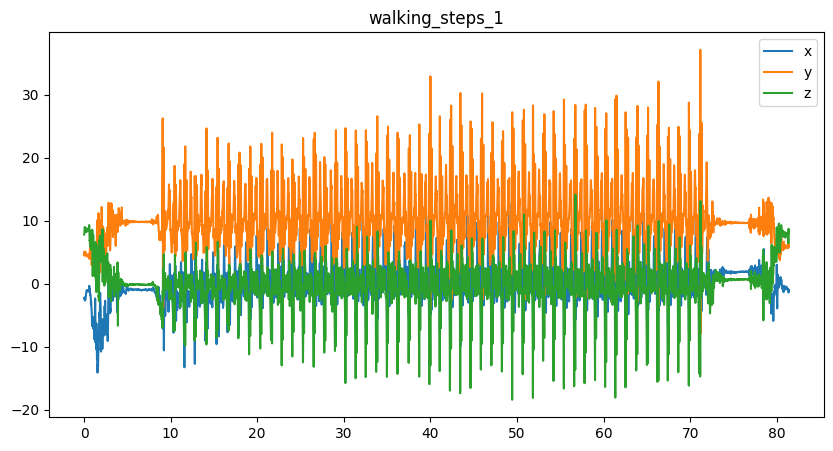

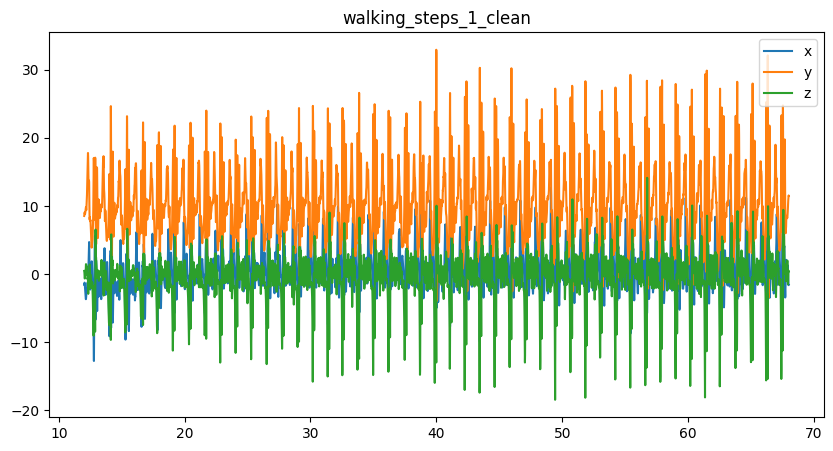

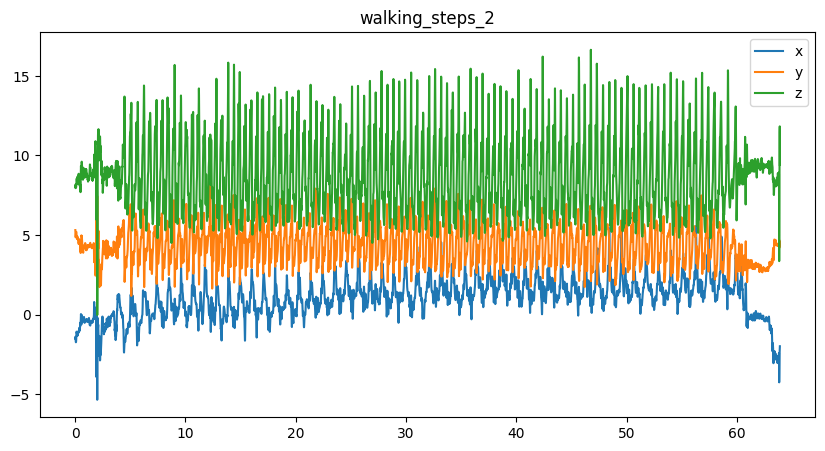

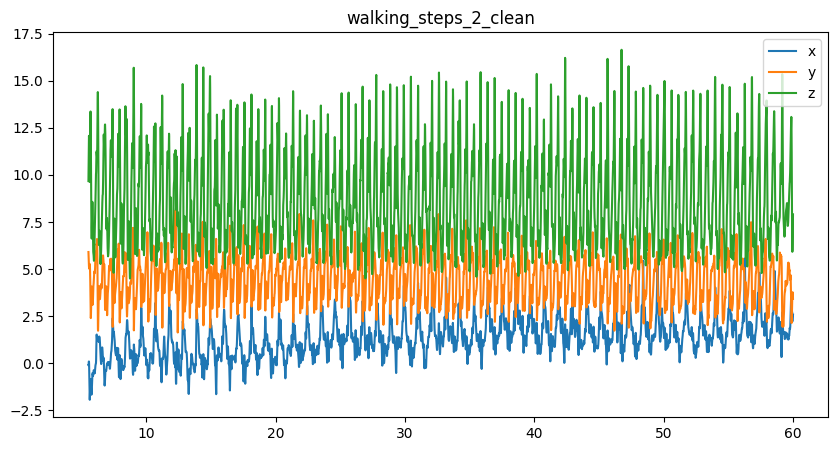

In [63]:
import parser_data

select_timestamp ={   # cutting the 3 second wait times at start and end of recording
     1: (12.0, 68.0),  # show data between 12 and 68 sec for first recording
     2: (5.5, 60.0),  # show data between 5.5 and 60 sec for 2nd recording
 }



def clean_data(data, num=None):
    # TODO: Write code to remove garbage data

    time_start, time_end = select_timestamp[num]
    cleaned_data = [row for row in data if time_start <= row[0] <= time_end]

    # Create new file without garbage data and save it in data folder
    file_name_clean = "walking_steps_clean.csv"
    if num is not None:
        file_name_clean = f"data/walking_steps_{num}_clean.csv"
        with open(file_name_clean, "w") as f:
            f.write("time,X,Y,Z\n")
            # TODO: write your cleaned data to the file
            for t, x, y, z in cleaned_data:
              f.write(f"{t}, {x}, {y}, {z}\n")



def main():
    # Get data
    for i in [1,2]:
        file_name = f"walking_steps_{i}.csv" # Change to your file name
        data = parser_data.get_data(file_name) #data -- time,X,Y,Z
        clean_data(data, i)
        newdata = parser_data.get_data(f"walking_steps_{i}_clean.csv")

        # TODO: Plot original and clean data
        plot_data(data, title=f"walking_steps_{i}")
        plot_data(newdata, title=f"walking_steps_{i}_clean")


if __name__== "__main__":
    main()



In [71]:
from scipy.signal import butter, lfilter
import numpy


def vector_magnitude(data):
    """
    Calculate the magnitude of the vector superposition of data (for
    example, acceleration) on x, y, and z axis

    Arguments:
        data: array of (x, y, z) tuples for a vector

    Returns:
        array of the magnitude of a vector

    TODO:
        Finish this function.
    """
    magnitudes = []             # empty list in order to loop magnitude sqrt X^2 + Y^2 + X^2 of each sample  , combine all 3 axes
    for row in data:
      if len(row) >= 4:
        x, y, z = row[1], row[2], row[3]
      else:
        x, y, z = row[0], row [1], row[2]
      magnitudes.append((x*x + y*y + z*z) ** 0.5)
    return magnitudes

    raise NotImplementedError


def moving_average(data, window_size):
    """ moving average filter

    Implement a simple moving average filter to use as a low pass
    filter

    Arguments:
        data: data be filtered
        window_size: window_size chosen for the data

    Returns:
        The filtered data.

    TODO:
        Finish this function. Think about how you want to handle
        the size difference between your input array and output array.
        You can write it yourself or consider using numpy.convole for
        it:
        https://docs.scipy.org/doc/numpy/reference/generated/numpy.convolve.html

    """
    data = numpy.asarray(data, dtype=float)                        # moving-avg low-pass filter via box kernel convolution
    kernel = numpy.ones(window_size) / window_size                 # heigh 1 per window size . output and input have same length
    return numpy.convolve(data, kernel, mode='same')

    raise NotImplementedError

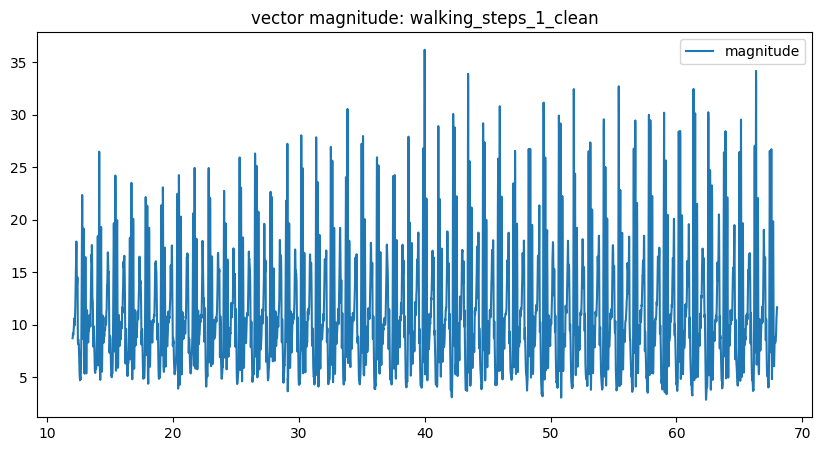

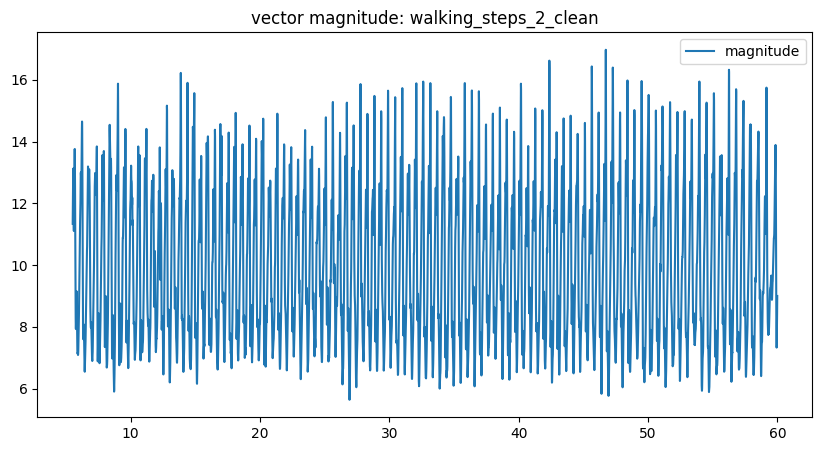

In [72]:
import parser_data

for i in [1, 2]:
  data = parser_data.get_data(f"walking_steps_{i}_clean.csv")
  time = [r[0] for r in data]
  magnitude = vector_magnitude(data)
  magnitude_plot = list(zip(time, magnitude))
  plot_data(magnitude_plot, labels=['magnitude'], title=f"vector magnitude: walking_steps_{i}_clean")

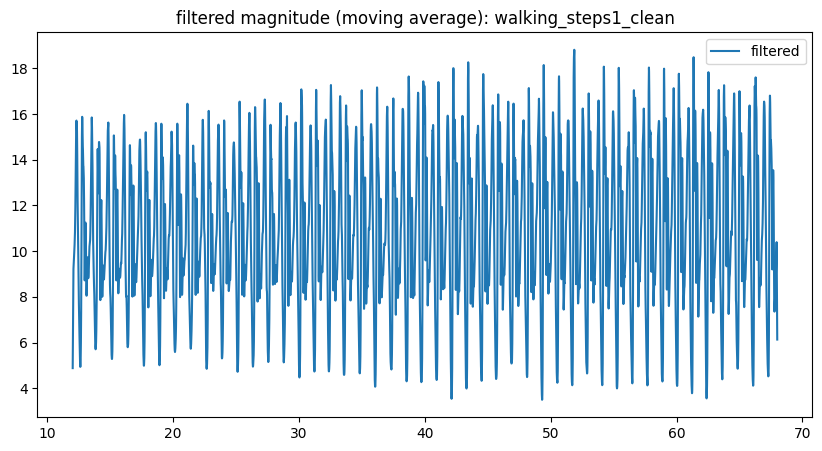

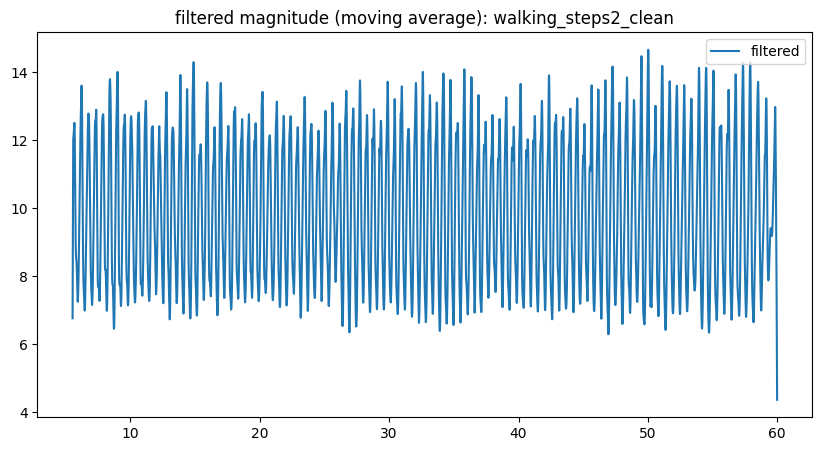

In [74]:
import parser_data

for i in [1, 2]:
  data = parser_data.get_data(f"walking_steps_{i}_clean.csv")
  time = [r[0] for r in data]
  magnitude = vector_magnitude(data)
  filtered = moving_average(magnitude, window_size=11)
  filtered_plot = list(zip(time, filtered))
  plot_data(filtered_plot, labels=['filtered'], title=f"filtered magnitude (moving average): walking_steps{i}_clean")

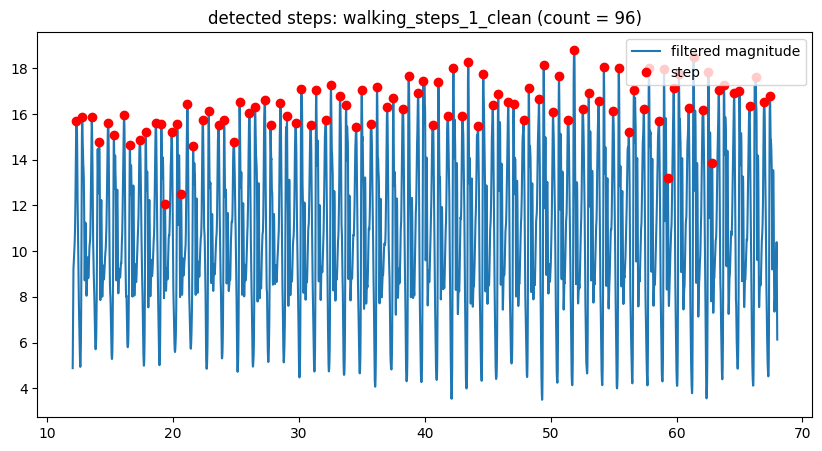

steps counted: 96


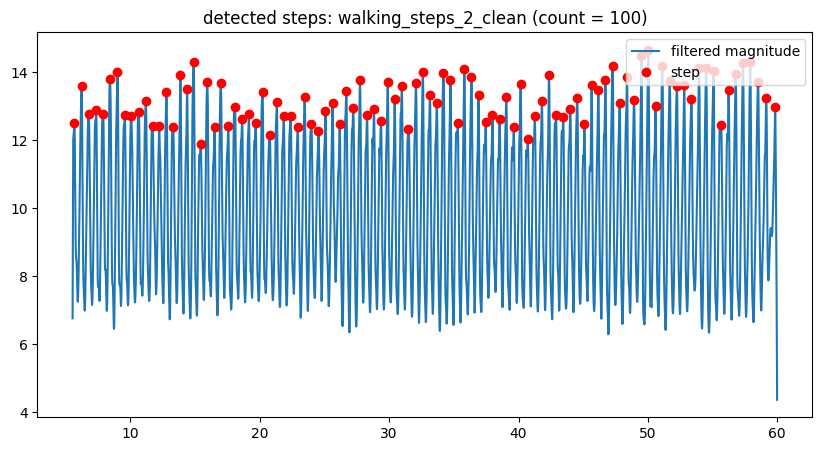

steps counted: 100


In [78]:
import parser_data
import numpy
from scipy.signal import find_peaks
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt

def count_steps(data, data_ID):
    '''
    Counts the number of steps in data and returns the number of steps
    '''
    # TODO: Complete this function.
    time = numpy.array([r[0] for r in data])           # task 3 c
    magnitude = vector_magnitude(data)
    filtered = moving_average(magnitude, window_size=11)

    height = filtered.mean() + 0.3 * filtered.std()      # peak threshold and spacing between steps
    difference_in_time = numpy.median(numpy.diff(time))
    distance = max(1, int(0.30 / difference_in_time))

    peaks, _ = find_peaks(filtered, height= height, distance= distance)
    plt.rcParams['figure.figsize'] = [10, 5]
    plt.title(f"detected steps: walking_steps_{data_ID}_clean (count = {len(peaks)})")
    plt.plot(time, filtered, label='filtered magnitude')
    plt.plot(time[peaks], filtered[peaks], 'ro', label='step')
    plt.legend(loc='upper right')
    plt.show()


    num_steps = len(peaks)
    return num_steps


def main():
    # Get data
    for i in [1,2]:
        file_name = f"walking_steps_{i}_clean.csv"
        data = parser_data.get_data(file_name)
        number_of_steps = count_steps(data, i)
        print("steps counted: {0:d}".format(number_of_steps))

if __name__== "__main__":
    main()



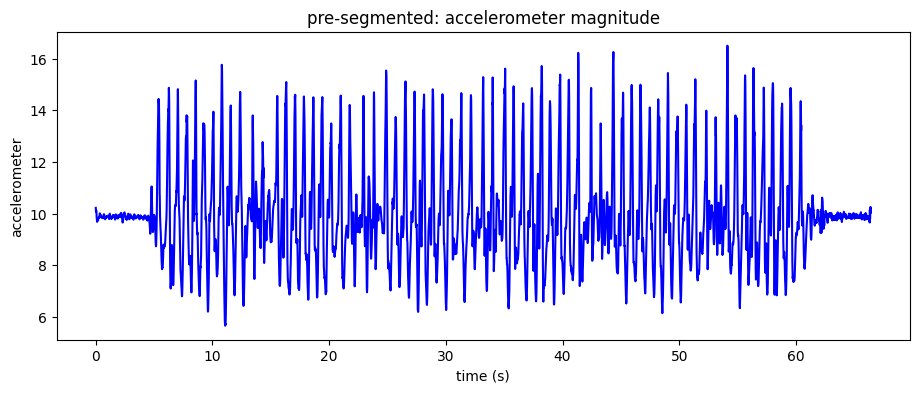

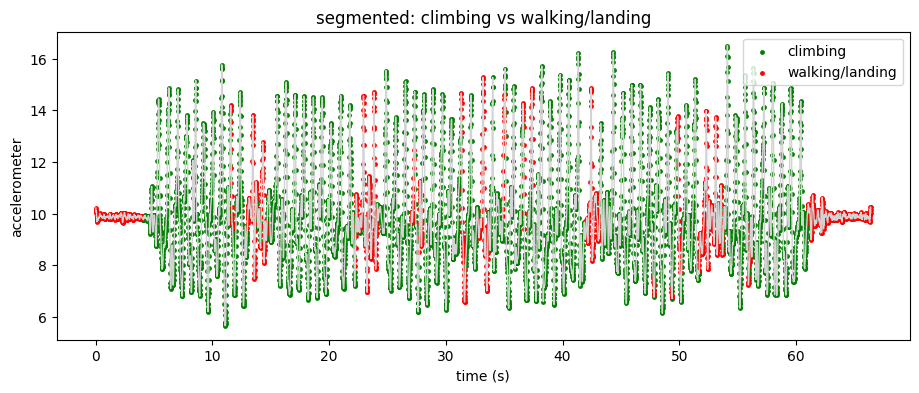

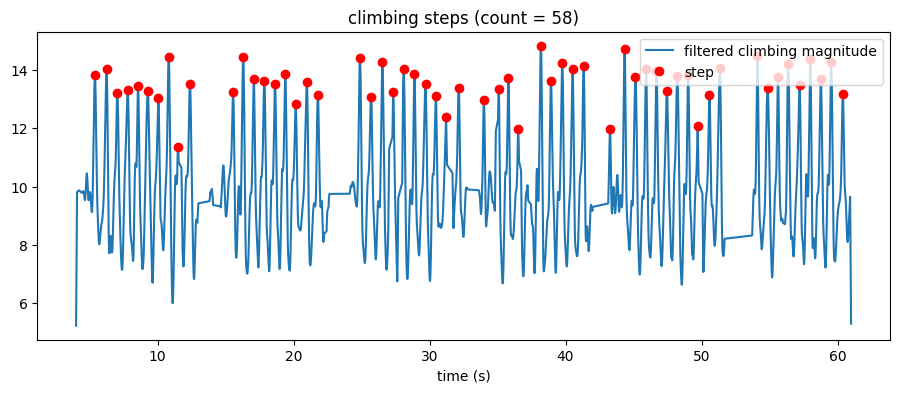

steps counted: 58


In [95]:
import parser_data
import numpy
from scipy.signal import find_peaks
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt


#def segment_climbing_walking(data):
def segment_climbing_walking(accelerometer_data, gyroscope_data):
    '''
    While collecting data on stairs there were times when you were also walking rather than climbing
    It is important to remove the parts from the data where you were walking in between the flight of stairs
    Write your own algorithm to find segments in data which corresponds to climbing only

    This functions returns
    List of tuples (x,y,z) which corresponds to climbing only.
    i.e. remove data points from the original data which corresponds to walking

    TODO: Complete this function.
    '''

    #print ('segment_climbing_walking')
    #plot_data(data)

    #return data
    accelerometer_times = numpy.array([r[0] for r in accelerometer_data])                                 ## Task 4 b
    accelerometer_magnitude = numpy.array(vector_magnitude(accelerometer_data))

    gyroscope_times = numpy.array([r[0] for r in gyroscope_data])
    gyroscope_yaw = numpy.abs(numpy.array([r[3] for r in gyroscope_data]))
    gyroscope_yaw_smooth = moving_average(gyroscope_yaw, 50)
    gyroscope_yaw_on_acc = numpy.interp(accelerometer_times, gyroscope_times, gyroscope_yaw_smooth)

    activity_start, activity_end, yaw_threshold = 4.0, 61.0, 0.82   # ignoring 3 seconds begninng and end (standing still) ; 0.82 is turning on a landing and below this threshold is climbing (this is read from sample data)
    activity = (accelerometer_times >= activity_start) & (accelerometer_times <= activity_end)
    is_climbing = activity & (gyroscope_yaw_on_acc < yaw_threshold)

    climbing = [accelerometer_data[i] for i in range(len(accelerometer_data)) if is_climbing[i]]

    plt.rcParams['figure.figsize'] = [11,4]
    plt.title("pre-segmented: accelerometer magnitude")
    plt.plot(accelerometer_times, accelerometer_magnitude, color='blue')
    plt.xlabel("time (s)"); plt.ylabel("accelerometer"); plt.show()

    plt.rcParams['figure.figsize'] = [11,4]
    plt.title("segmented: climbing vs walking/landing")
    plt.plot(accelerometer_times, accelerometer_magnitude, color='lightgray', linewidth= 1)
    plt.scatter(accelerometer_times[is_climbing], accelerometer_magnitude[is_climbing], s= 6, color='green', label='climbing')
    plt.scatter(accelerometer_times[~is_climbing], accelerometer_magnitude[~is_climbing], s= 6, color='red', label='walking/landing')
    plt.legend(loc='upper right'); plt.xlabel("time (s)"); plt.ylabel("accelerometer"); plt.show()

    return climbing


def count_steps(data):
    #print ('count_steps')
    #num_steps = 0
    '''
    This function counts the number of steps in data and returns the number of steps
    TODO: Complete this function.
    '''
    #return num_steps
    time = numpy.array([r[0] for r in data])                             # reused from above
    filtered = moving_average(vector_magnitude(data), 15)

    height = filtered.mean() + 0.5 * filtered.std()
    difference_in_time = numpy.median(numpy.diff(time))
    distance = max(1, int(0.30 / difference_in_time))
    peaks, _ = find_peaks(filtered, height=height, distance=distance)

    plt.rcParams['figure.figsize'] = [11, 4]
    plt.title(f"climbing steps (count = {len(peaks)})")
    plt.plot(time, filtered, label='filtered climbing magnitude')
    plt.plot(time[peaks], filtered[peaks], 'ro', label='step')
    plt.legend(loc='upper right'); plt.xlabel("time (s)"); plt.show()

    return len(peaks)


def main():
    # Get data
    #file_name = "test.csv"  # Change this to your data file name
    #data = parser_data.get_data(file_name)

    #segmented_data = segment_climbing_walking(data)
    #number_of_steps = count_steps(segmented_data)
    #print ("Number of steps counted are :{0:d}".format(number_of_steps))

    accelero = parser_data.get_data("stairs_1.csv")
    gyro = parser_data.get_data("stairs_2.csv")

    segmented_data = segment_climbing_walking(accelero, gyro)
    number_of_steps = count_steps(segmented_data)
    print ("steps counted: {0:d}".format(number_of_steps))


if __name__== "__main__":
    main()
